<a href="https://colab.research.google.com/github/rwalden-gif/IntroToML/blob/main/Homework7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import time
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
from torchvision import datasets

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

Using: cuda


In [2]:
train_set = datasets.CIFAR10(root="data", train=True, download=True)
test_set = datasets.CIFAR10(root="data", train=False, download=True)

X_train = torch.tensor(train_set.data, dtype=torch.float32) / 255
X_test = torch.tensor(test_set.data, dtype=torch.float32) / 255
X_train = ((X_train - 0.5) / 0.5).reshape(len(X_train), -1).to(device)
X_test = ((X_test - 0.5) / 0.5).reshape(len(X_test), -1).to(device)
y_train = torch.tensor(train_set.targets).to(device)
y_test = torch.tensor(test_set.targets).to(device)

print("Training images:", X_train.shape)
print("Test images:", X_test.shape)

100%|██████████| 170M/170M [42:05<00:00, 67.5kB/s]


Training images: torch.Size([50000, 3072])
Test images: torch.Size([10000, 3072])


In [3]:
epochs = 40
batch_size = 128
learning_rate = 0.001
width = 512

def make_net(hidden_layers, hidden_size, activation):
    layers = []
    size = 3072
    for i in range(hidden_layers):
        layers.append(nn.Linear(size, hidden_size))
        layers.append(activation())
        size = hidden_size
    layers.append(nn.Linear(size, 10))
    return nn.Sequential(*layers)

def accuracy(net, X, y):
    net.eval()
    with torch.no_grad():
        guesses = net(X).argmax(dim=1)
    return (guesses == y).float().mean().item()

def train_net(net):
    net = net.to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(net.parameters(), lr=learning_rate)
    losses = []
    train_accs = []
    test_accs = []
    start = time.time()
    for epoch in range(epochs):
        net.train()
        order = torch.randperm(len(X_train), device=device)
        total_loss = 0
        for i in range(0, len(X_train), batch_size):
            pick = order[i:i + batch_size]
            loss = loss_fn(net(X_train[pick]), y_train[pick])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(pick)
        losses.append(total_loss / len(X_train))
        train_accs.append(accuracy(net, X_train, y_train))
        test_accs.append(accuracy(net, X_test, y_test))
    seconds = time.time() - start
    params = sum(p.numel() for p in net.parameters() if p.requires_grad)
    return {"losses": losses, "train_accs": train_accs, "test_accs": test_accs,
            "seconds": seconds, "params": params}

results = {}

In [4]:
results["1.a Baseline"] = train_net(make_net(2, width, nn.ReLU))
r = results["1.a Baseline"]
print("Time:", round(r["seconds"], 1), "seconds")
print("Train loss:", round(r["losses"][-1], 4))
print("Train accuracy:", round(r["train_accs"][-1], 4))
print("Test accuracy:", round(r["test_accs"][-1], 4))
print("Parameters:", r["params"])

Time: 31.4 seconds
Train loss: 0.1206
Train accuracy: 0.9585
Test accuracy: 0.5281
Parameters: 1841162


In [5]:
results["1.b Four layers"] = train_net(make_net(4, width, nn.ReLU))
r = results["1.b Four layers"]
print("Time:", round(r["seconds"], 1), "seconds")
print("Train loss:", round(r["losses"][-1], 4))
print("Train accuracy:", round(r["train_accs"][-1], 4))
print("Test accuracy:", round(r["test_accs"][-1], 4))
print("Parameters:", r["params"])

Time: 40.5 seconds
Train loss: 0.1586
Train accuracy: 0.9636
Test accuracy: 0.5306
Parameters: 2366474


In [6]:
results["2.a Ten layers"] = train_net(make_net(10, width, nn.ReLU))
r = results["2.a Ten layers"]
print("Time:", round(r["seconds"], 1), "seconds")
print("Train loss:", round(r["losses"][-1], 4))
print("Train accuracy:", round(r["train_accs"][-1], 4))
print("Test accuracy:", round(r["test_accs"][-1], 4))
print("Parameters:", r["params"])

Time: 68.3 seconds
Train loss: 0.2045
Train accuracy: 0.9443
Test accuracy: 0.5228
Parameters: 3942410


In [7]:
results["2.b Double width"] = train_net(make_net(2, width * 2, nn.ReLU))
results["2.b Sigmoid"] = train_net(make_net(2, width, nn.Sigmoid))
results["2.b Tanh"] = train_net(make_net(2, width, nn.Tanh))
for name in ["2.b Double width", "2.b Sigmoid", "2.b Tanh"]:
    r = results[name]
    print(name)
    print("Time:", round(r["seconds"], 1), "seconds")
    print("Train loss:", round(r["losses"][-1], 4))
    print("Train accuracy:", round(r["train_accs"][-1], 4))
    print("Test accuracy:", round(r["test_accs"][-1], 4))
    print("Parameters:", r["params"])

2.b Double width
Time: 46.6 seconds
Train loss: 0.1356
Train accuracy: 0.9599
Test accuracy: 0.5357
Parameters: 4206602
2.b Sigmoid
Time: 30.6 seconds
Train loss: 0.1061
Train accuracy: 0.953
Test accuracy: 0.4761
Parameters: 1841162
2.b Tanh
Time: 32.7 seconds
Train loss: 0.2107
Train accuracy: 0.9373
Test accuracy: 0.4721
Parameters: 1841162


In [8]:
table = pd.DataFrame({
    "Epochs": epochs,
    "Time (s)": [round(r["seconds"], 1) for r in results.values()],
    "Train loss": [round(r["losses"][-1], 4) for r in results.values()],
    "Train acc": [round(r["train_accs"][-1], 4) for r in results.values()],
    "Test acc": [round(r["test_accs"][-1], 4) for r in results.values()],
    "Best test acc": [round(max(r["test_accs"]), 4) for r in results.values()],
    "Best epoch": [r["test_accs"].index(max(r["test_accs"])) + 1
                   for r in results.values()],
    "Parameters": [r["params"] for r in results.values()],
}, index=list(results.keys()))
table

,Epochs,Time (s),Train loss,Train acc,Test acc,Best test acc,Best epoch,Parameters
1.a Baseline,40,31.4,0.1206,0.9585,0.5281,0.5486,9,1841162
1.b Four layers,40,40.5,0.1586,0.9636,0.5306,0.5494,26,2366474
2.a Ten layers,40,68.3,0.2045,0.9443,0.5228,0.5360,19,3942410
2.b Double width,40,46.6,0.1356,0.9599,0.5357,0.5419,8,4206602
2.b Sigmoid,40,30.6,0.1061,0.9530,0.4761,0.5126,10,1841162
2.b Tanh,40,32.7,0.2107,0.9373,0.4721,0.4975,12,1841162


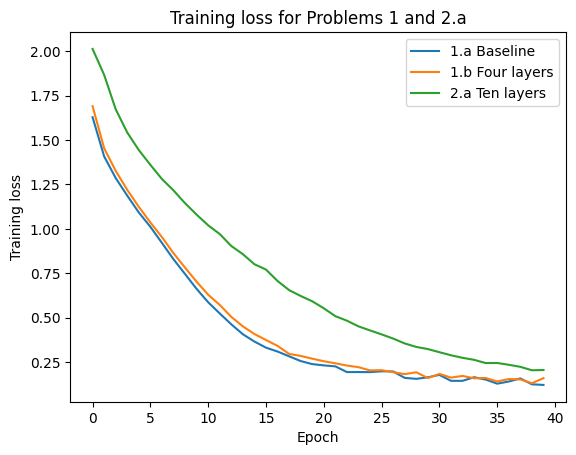

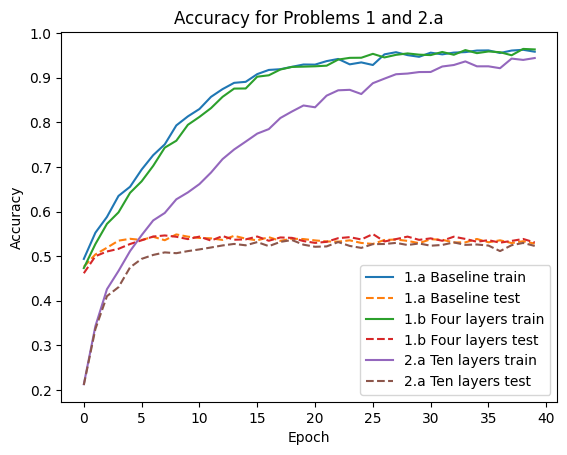

In [9]:
first = ["1.a Baseline", "1.b Four layers", "2.a Ten layers"]
for name in first:
    plt.plot(results[name]["losses"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training loss for Problems 1 and 2.a")
plt.legend()
plt.show()

for name in first:
    plt.plot(results[name]["train_accs"], label=name + " train")
    plt.plot(results[name]["test_accs"], "--", label=name + " test")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy for Problems 1 and 2.a")
plt.legend()
plt.show()

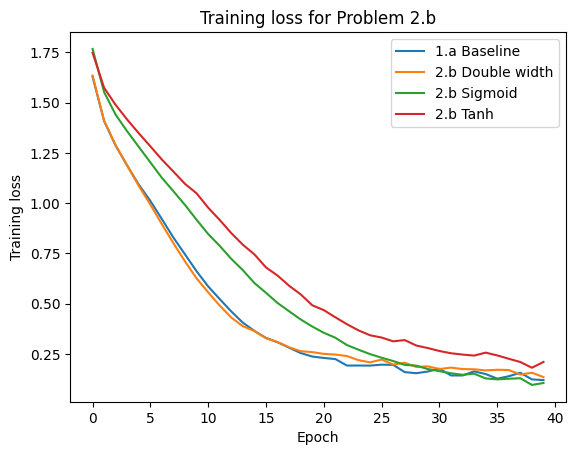

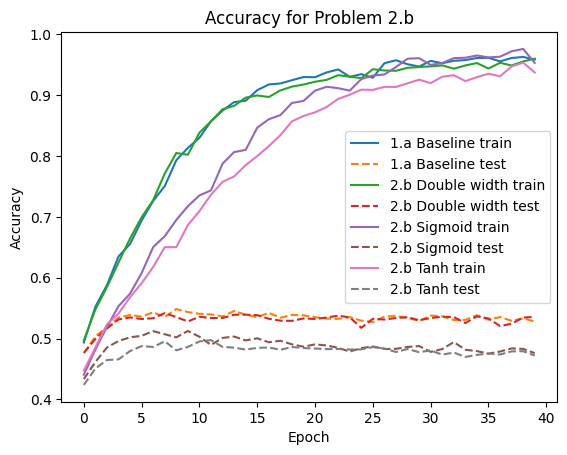

In [10]:
second = ["1.a Baseline", "2.b Double width", "2.b Sigmoid", "2.b Tanh"]
for name in second:
    plt.plot(results[name]["losses"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training loss for Problem 2.b")
plt.legend()
plt.show()

for name in second:
    plt.plot(results[name]["train_accs"], label=name + " train")
    plt.plot(results[name]["test_accs"], "--", label=name + " test")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy for Problem 2.b")
plt.legend()
plt.show()